# Concealed Weapon Detection (CWD)

This notebook develops and evaluates the PMMW concealed-weapon object-detection component of the multi-modal threat prediction system.

## Planned workflow

1. Audit and clean the PMMW dataset
2. Visualise images and bounding-box annotations
3. Create leakage-safe training, validation and test splits
4. Convert annotations to the detector's required format
5. Train a lightweight object-detection baseline
6. Evaluate detection accuracy, errors and edge-deployment cost
7. Compare controlled improvements and select the final CWD model

## 1. Dataset setup and parsing

The PMMW dataset uses Pascal VOC XML annotations. The following cells parse every image, object label and bounding box into simple pandas DataFrames.

In [78]:
from pathlib import Path
import hashlib
import filecmp
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

SEED = 42
DATASET_ROOT = Path("pmmw-dataset")
if not DATASET_ROOT.exists():
    DATASET_ROOT = Path("CWD") / DATASET_ROOT

IMAGE_DIR = DATASET_ROOT / "images"
ANNOTATION_DIR = DATASET_ROOT / "Annotations"

if not IMAGE_DIR.exists() or not ANNOTATION_DIR.exists():
    raise FileNotFoundError(f"PMMW dataset not found at {DATASET_ROOT.resolve()}")

In [79]:
image_paths = sorted(IMAGE_DIR.glob("*.jpg"))
xml_paths = sorted(ANNOTATION_DIR.glob("*.xml"))
records = []

for xml_path in xml_paths:
    root = ET.parse(xml_path).getroot()
    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    for obj in root.findall("object"):
        box = obj.find("bndbox")
        xmin, ymin, xmax, ymax = [
            int(box.findtext(name)) for name in ("xmin", "ymin", "xmax", "ymax")
        ]
        records.append({
            "image_name": f"{xml_path.stem}.jpg",
            "class_name": obj.findtext("name").strip().lower(),
            "width": width, "height": height,
            "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax,
        })

annotations = pd.DataFrame(records)
annotations["box_width"] = annotations["xmax"] - annotations["xmin"]
annotations["box_height"] = annotations["ymax"] - annotations["ymin"]
annotations["relative_box_area"] = (
    annotations["box_width"] * annotations["box_height"]
    / (annotations["width"] * annotations["height"])
)
annotations["invalid_box"] = (
    (annotations["xmin"] < 0) | (annotations["ymin"] < 0)
    | (annotations["xmax"] > annotations["width"])
    | (annotations["ymax"] > annotations["height"])
    | (annotations["box_width"] <= 0) | (annotations["box_height"] <= 0)
)

per_image = annotations.groupby("image_name").agg(
    object_count=("class_name", "size"),
    classes=("class_name", lambda values: ", ".join(sorted(set(values)))),
    has_gun=("class_name", lambda values: "gun" in set(values)),
).reset_index()

images = pd.DataFrame({
    "image_name": [path.name for path in image_paths],
    "image_path": image_paths,
}).merge(per_image, on="image_name", how="left")
images["has_annotation"] = images["object_count"].notna()
images["object_count"] = images["object_count"].fillna(0).astype(int)
images["has_gun"] = images["has_gun"].fillna(False).astype(bool)

C:\Users\ADAM-\AppData\Local\Temp\ipykernel_3900\168049619.py:48: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  images["has_gun"] = images["has_gun"].fillna(False).astype(bool)


## 2. Dataset statistics

In [80]:
image_names = {path.stem for path in image_paths}
xml_names = {path.stem for path in xml_paths}
missing_xml = sorted(image_names - xml_names)
missing_images = sorted(xml_names - image_names)
annotated_images = images[images["has_annotation"]]

print(f"Image files:             {len(image_paths):,}")
print(f"XML annotation files:    {len(xml_paths):,}")
print(f"Total bounding boxes:    {len(annotations):,}")
print(f"Gun-positive images:     {annotated_images['has_gun'].sum():,}")
print(f"Gun-negative images:     {(~annotated_images['has_gun']).sum():,}")
print(f"Images without XML:      {len(missing_xml):,}")
print(f"XML files without image: {len(missing_images):,}")
print(f"Invalid bounding boxes:  {annotations['invalid_box'].sum():,}")
print(f"Image dimensions:        {sorted(set(zip(annotations.width, annotations.height)))}")

if missing_xml:
    print("\nImages without annotations:", ", ".join(missing_xml))

Image files:             1,624
XML annotation files:    1,618
Total bounding boxes:    2,445
Gun-positive images:     833
Gun-negative images:     785
Images without XML:      6
XML files without image: 0
Invalid bounding boxes:  0
Image dimensions:        [(284, 631), (286, 635)]

Images without annotations: image_0105, image_0417, image_0419, image_0492, image_1060, image_1468


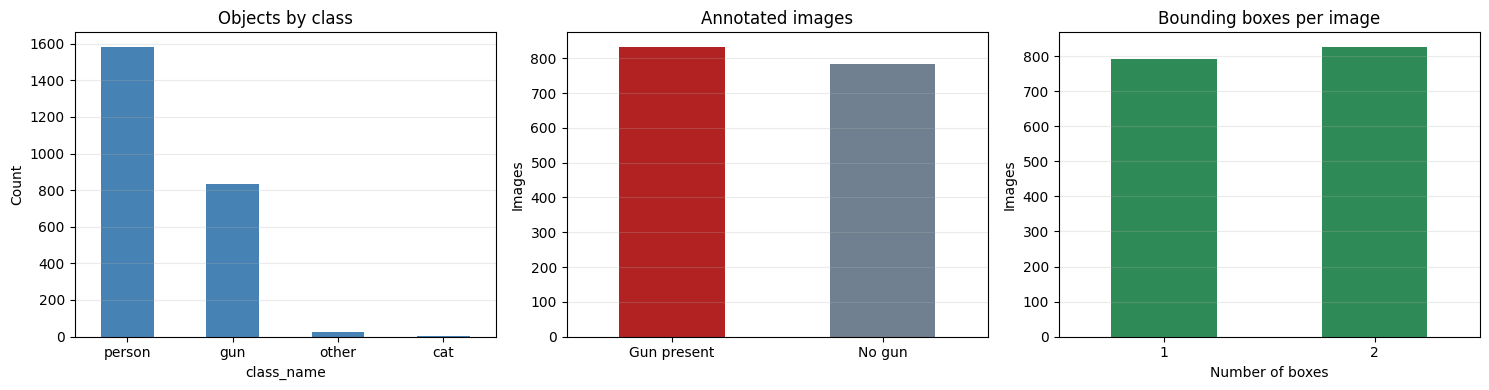

In [81]:
class_counts = annotations["class_name"].value_counts().sort_values(ascending=False)
gun_status = pd.Series({
    "Gun present": int(annotated_images["has_gun"].sum()),
    "No gun": int((~annotated_images["has_gun"]).sum()),
})
boxes_per_image = annotated_images["object_count"].value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
class_counts.plot.bar(ax=axes[0], color="steelblue", title="Objects by class")
gun_status.plot.bar(ax=axes[1], color=["firebrick", "slategray"], title="Annotated images")
boxes_per_image.plot.bar(ax=axes[2], color="seagreen", title="Bounding boxes per image")
axes[0].set_ylabel("Count")
axes[1].set_ylabel("Images")
axes[2].set(xlabel="Number of boxes", ylabel="Images")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Annotation examples

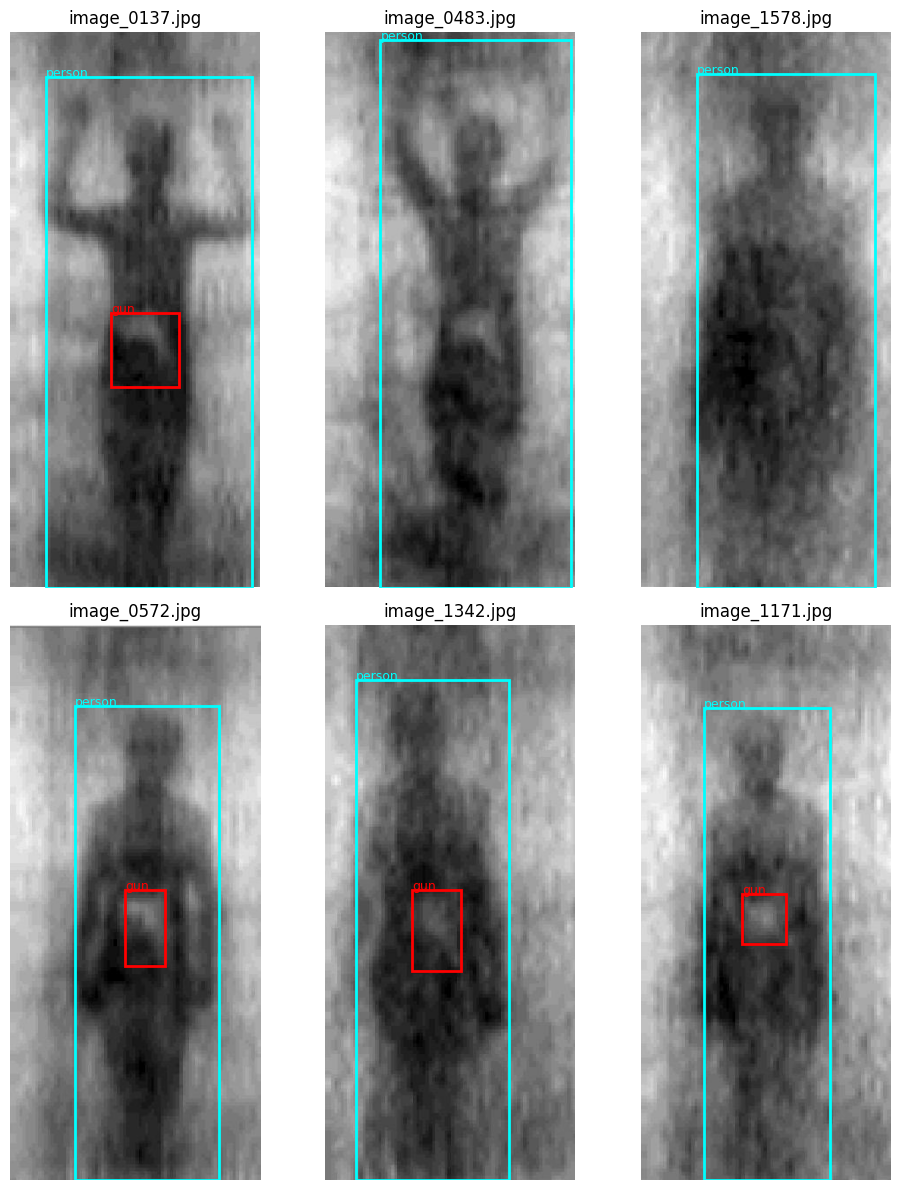

In [82]:
sample_names = annotated_images.sample(6, random_state=SEED)["image_name"]
colours = {"gun": "red", "person": "cyan", "other": "orange", "cat": "yellow"}
fig, axes = plt.subplots(2, 3, figsize=(10, 12))

for ax, image_name in zip(axes.flat, sample_names):
    ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
    for _, box in annotations[annotations["image_name"] == image_name].iterrows():
        colour = colours.get(box["class_name"], "lime")
        ax.add_patch(Rectangle(
            (box["xmin"], box["ymin"]), box["box_width"], box["box_height"],
            fill=False, edgecolor=colour, linewidth=2,
        ))
        ax.text(box["xmin"], box["ymin"], box["class_name"], color=colour, fontsize=9)
    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Exact duplicate detection

Each image is hashed using SHA-256 over its complete file contents. Files sharing a hash are then compared byte-for-byte. This detects only exact copies; visually similar frames are not counted.

In [83]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

images["sha256"] = images["image_path"].apply(sha256_file)
duplicate_groups = images.groupby("sha256")["image_path"].apply(list)
duplicate_groups = duplicate_groups[duplicate_groups.apply(len) > 1]

# Confirm every hash match by comparing the complete file contents.
for paths in duplicate_groups:
    if not all(filecmp.cmp(paths[0], path, shallow=False) for path in paths[1:]):
        raise RuntimeError("A hash group failed byte-for-byte verification.")

duplicate_files = sum(len(paths) for paths in duplicate_groups)
extra_copies = sum(len(paths) - 1 for paths in duplicate_groups)

print("Duplicate method: SHA-256 + byte-for-byte verification")
print(f"Exact duplicate groups:  {len(duplicate_groups):,}")
print(f"Files in those groups:   {duplicate_files:,}")
print(f"Extra duplicate copies:  {extra_copies:,}")
print(f"Unique image contents:   {images['sha256'].nunique():,}")
print("Verification:            all duplicate groups are byte-identical")

print("\nExample duplicate groups:")
for paths in duplicate_groups.head(5):
    print("  " + ", ".join(path.name for path in paths))

Duplicate method: SHA-256 + byte-for-byte verification
Exact duplicate groups:  305
Files in those groups:   736
Extra duplicate copies:  431
Unique image contents:   1,193
Verification:            all duplicate groups are byte-identical

Example duplicate groups:
  image_0243.jpg, image_0249.jpg
  image_0935.jpg, image_0937.jpg
  image_1030.jpg, image_1031.jpg
  image_0467.jpg, image_0475.jpg
  image_0730.jpg, image_1123.jpg


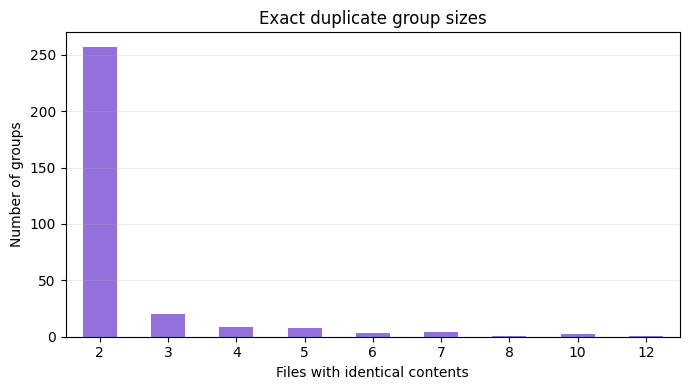

In [84]:
group_sizes = duplicate_groups.apply(len).value_counts().sort_index()
ax = group_sizes.plot.bar(figsize=(7, 4), color="mediumpurple")
ax.set(title="Exact duplicate group sizes", xlabel="Files with identical contents", ylabel="Number of groups")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

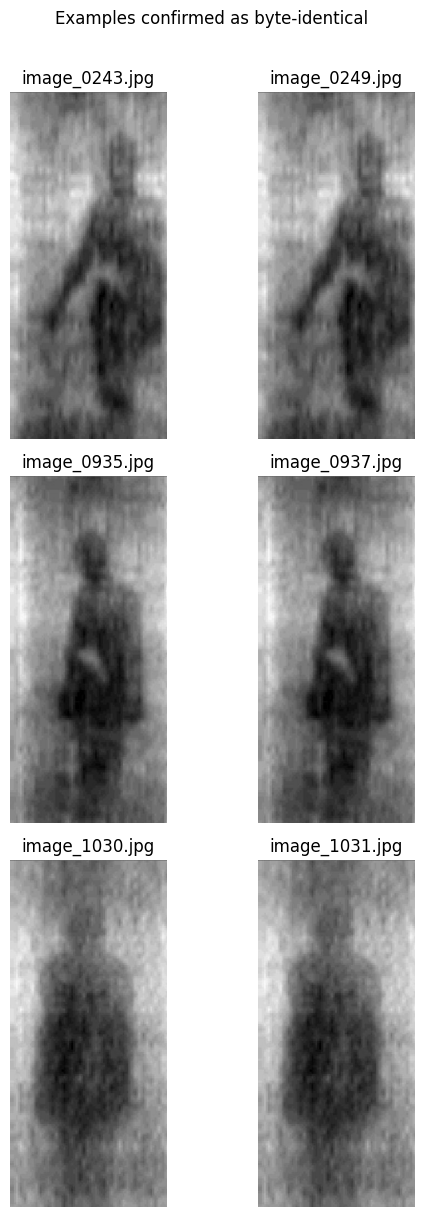

In [85]:
examples = duplicate_groups.head(3).tolist()
if examples:
    fig, axes = plt.subplots(len(examples), 2, figsize=(6, 4 * len(examples)))
    if len(examples) == 1:
        axes = [axes]
    for row, paths in zip(axes, examples):
        for ax, path in zip(row, paths[:2]):
            ax.imshow(Image.open(path), cmap="gray")
            ax.set_title(path.name)
            ax.axis("off")
    fig.suptitle("Examples confirmed as byte-identical", y=1.01)
    plt.tight_layout()
    plt.show()

## 5. Remove exact duplicates from the working dataset

This creates deduplicated `clean_images` and `clean_annotations` DataFrames. It excludes the six unannotated noise images, all 32 unique images with contradictory gun labels, and the 23 images labelled `cat` or `other`. The original image and XML files are left unchanged. For the remaining identical-image groups, preference is given to an annotated copy and then the copy with the most annotations.

In [86]:
duplicate_rows = images[images["sha256"].isin(duplicate_groups.index) & images["has_annotation"]]
class_conflicts = duplicate_rows.groupby("sha256")["classes"].nunique().gt(1).sum()
gun_conflict_mask = duplicate_rows.groupby("sha256")["has_gun"].nunique().gt(1)
gun_conflict_hashes = set(gun_conflict_mask[gun_conflict_mask].index)
gun_conflicts = len(gun_conflict_hashes)

# Select one representative for each unique file hash.
representatives = (
    images.sort_values(
        ["has_annotation", "has_gun", "object_count", "image_name"],
        ascending=[False, False, False, True],
    )
    .drop_duplicates("sha256")
    .sort_values("image_name")
    .reset_index(drop=True)
)

kept_names = set(representatives["image_name"])
kept_by_hash = representatives.set_index("sha256")["image_name"]
duplicate_manifest = images[~images["image_name"].isin(kept_names)].copy()
duplicate_manifest["kept_image_name"] = duplicate_manifest["sha256"].map(kept_by_hash)
duplicate_manifest = duplicate_manifest[["image_name", "kept_image_name", "sha256"]]

unannotated_noise = {
    "image_0105.jpg", "image_0417.jpg", "image_0419.jpg",
    "image_0492.jpg", "image_1060.jpg", "image_1468.jpg",
}

removed_noise = sorted(unannotated_noise & kept_names)
removed_conflicts = sorted(
    representatives.loc[representatives["sha256"].isin(gun_conflict_hashes), "image_name"]
)
unusual_class_names = set(
    annotations.loc[annotations["class_name"].isin(["cat", "other"]), "image_name"]
)
removed_unusual = sorted(
    (unusual_class_names & kept_names) - set(removed_noise) - set(removed_conflicts)
)

clean_images = representatives[
    ~representatives["image_name"].isin(removed_noise)
    & ~representatives["sha256"].isin(gun_conflict_hashes)
    & ~representatives["image_name"].isin(removed_unusual)
].copy().reset_index(drop=True)
clean_names = set(clean_images["image_name"])
clean_annotations = annotations[annotations["image_name"].isin(clean_names)].copy().reset_index(drop=True)

assert len(clean_images) == (
    images["sha256"].nunique() - len(removed_noise) - len(gun_conflict_hashes) - len(removed_unusual)
)
assert len(duplicate_manifest) == extra_copies
assert clean_images["sha256"].is_unique
assert not set(clean_images["sha256"]) & gun_conflict_hashes
assert not set(clean_images["image_name"]) & unusual_class_names

print(f"Images before deduplication:       {len(images):,}")
print(f"Exact duplicate copies excluded:  {len(duplicate_manifest):,}")
print(f"Unannotated noise images excluded:{len(removed_noise):>3,}")
print(f"Gun-conflict images excluded:     {len(removed_conflicts):,}")
print(f"Cat/other images excluded:        {len(removed_unusual):,}")
print(f"Unique images remaining:          {len(clean_images):,}")
print(f"Bounding boxes remaining:         {len(clean_annotations):,}")
print(f"Groups with class disagreements:  {class_conflicts:,}")
print(f"Groups disagreeing on gun label:  {gun_conflicts:,}")
print("Original files changed:            no")

Images before deduplication:       1,624
Exact duplicate copies excluded:  431
Unannotated noise images excluded:  6
Gun-conflict images excluded:     32
Cat/other images excluded:        23
Unique images remaining:          1,132
Bounding boxes remaining:         1,725
Groups with class disagreements:  33
Groups disagreeing on gun label:  32
Original files changed:            no


## 6. Review gun-label disagreements

These are the 32 groups excluded from the clean dataset because one XML file includes a gun and another does not for the same byte-identical image. Each row shows a gun-labelled version beside a no-gun version. Change `REVIEW_PAGE` from 1 to 8 and rerun the display cell to inspect the rejected groups.

In [87]:
gun_label_counts = duplicate_rows.groupby("sha256")["has_gun"].nunique()
gun_conflict_hashes = gun_label_counts[gun_label_counts > 1].index.tolist()
gun_conflict_hashes.sort(key=lambda value: images.loc[images["sha256"] == value, "image_name"].min())

gun_review_groups = []
for group_number, file_hash in enumerate(gun_conflict_hashes, start=1):
    versions = images[images["sha256"] == file_hash].sort_values("image_name")
    gun_versions = versions[versions["has_gun"]]["image_name"].tolist()
    no_gun_versions = versions[~versions["has_gun"]]["image_name"].tolist()
    gun_review_groups.append({
        "group": group_number,
        "sha256": file_hash,
        "gun_versions": gun_versions,
        "no_gun_versions": no_gun_versions,
    })

assert len(gun_review_groups) == 32
print(f"Gun-label disagreement groups ready for review: {len(gun_review_groups)}")

Gun-label disagreement groups ready for review: 32


Group 1: gun = image_0028.jpg; no gun = image_0024.jpg
Group 2: gun = image_0067.jpg; no gun = image_0063.jpg
Group 3: gun = image_0115.jpg; no gun = image_0121.jpg
Group 4: gun = image_1167.jpg; no gun = image_0275.jpg


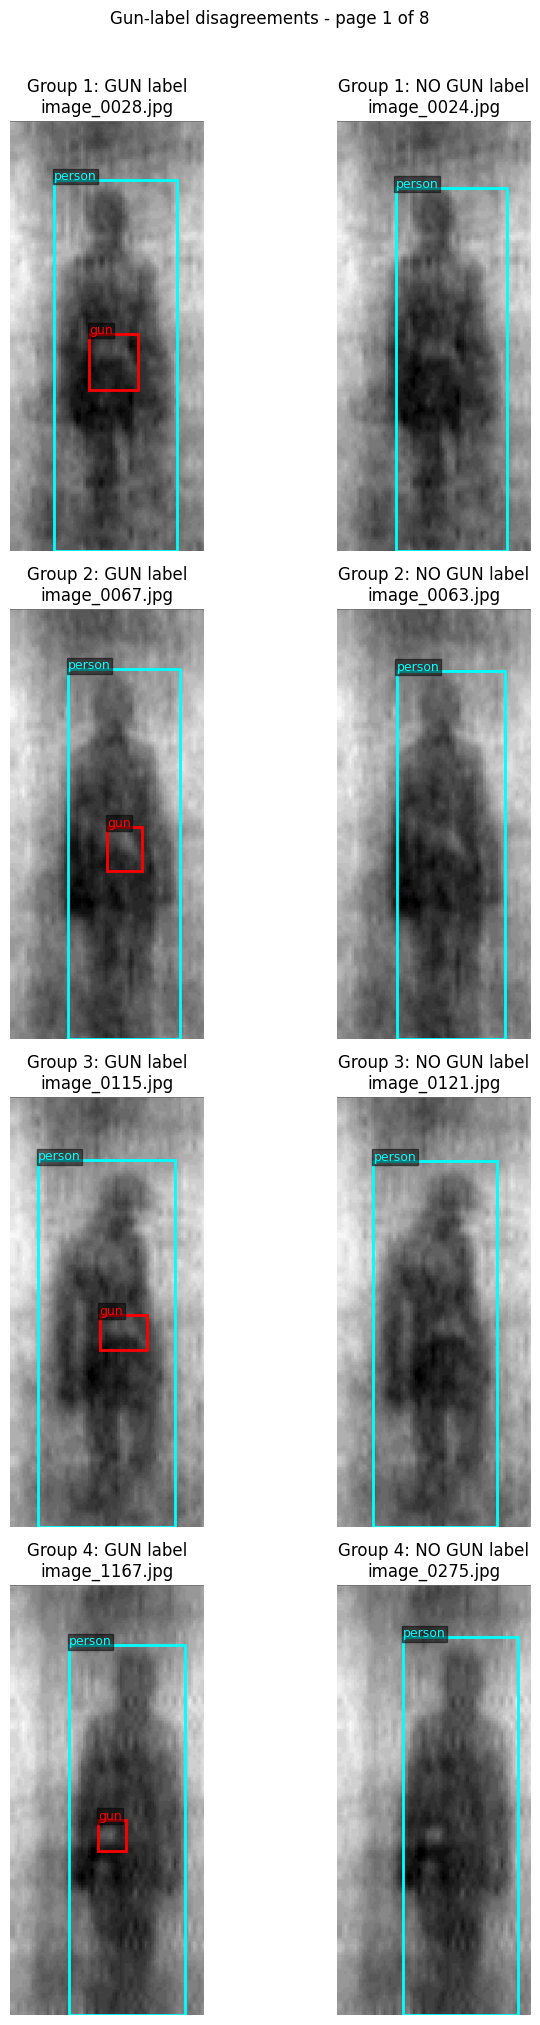

In [88]:
REVIEW_PAGE = 1
GROUPS_PER_PAGE = 4
total_pages = (len(gun_review_groups) + GROUPS_PER_PAGE - 1) // GROUPS_PER_PAGE

if not 1 <= REVIEW_PAGE <= total_pages:
    raise ValueError(f"REVIEW_PAGE must be between 1 and {total_pages}.")

def draw_annotation_version(ax, image_name):
    ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
    for _, box in annotations[annotations["image_name"] == image_name].iterrows():
        colour = "red" if box["class_name"] == "gun" else "cyan"
        ax.add_patch(Rectangle(
            (box["xmin"], box["ymin"]), box["box_width"], box["box_height"],
            fill=False, edgecolor=colour, linewidth=2,
        ))
        ax.text(
            box["xmin"], box["ymin"], box["class_name"], color=colour, fontsize=9,
            bbox={"facecolor": "black", "alpha": 0.5, "pad": 1},
        )
    ax.axis("off")

start = (REVIEW_PAGE - 1) * GROUPS_PER_PAGE
page_groups = gun_review_groups[start:start + GROUPS_PER_PAGE]
fig, axes = plt.subplots(len(page_groups), 2, figsize=(8, 5 * len(page_groups)), squeeze=False)

for row, group in zip(axes, page_groups):
    gun_example = group["gun_versions"][0]
    no_gun_example = group["no_gun_versions"][0]
    draw_annotation_version(row[0], gun_example)
    draw_annotation_version(row[1], no_gun_example)
    row[0].set_title(f"Group {group['group']}: GUN label\n{gun_example}")
    row[1].set_title(f"Group {group['group']}: NO GUN label\n{no_gun_example}")
    print(
        f"Group {group['group']}: gun = {', '.join(group['gun_versions'])}; "
        f"no gun = {', '.join(group['no_gun_versions'])}"
    )

fig.suptitle(f"Gun-label disagreements - page {REVIEW_PAGE} of {total_pages}", y=1.01)
plt.tight_layout()
plt.show()

## Image display helper

In [89]:
def show_images(image_names, columns=4):
    if not image_names:
        print("No image names provided.")
        return

    columns = max(1, min(columns, len(image_names)))
    rows = (len(image_names) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 6 * rows), squeeze=False)

    for ax, image_name in zip(axes.flat, image_names):
        image_path = IMAGE_DIR / image_name
        if image_path.exists():
            ax.imshow(Image.open(image_path), cmap="gray")
            ax.set_title(image_name)
        else:
            ax.set_title(f"Missing: {image_name}", color="red")
        ax.axis("off")

    for ax in axes.flat[len(image_names):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Example:
# show_images(["image_0028.jpg", "image_0100.jpg"])



### Excluded images labelled `cat` or `other`

In [90]:
# unusual_class_images = removed_unusual

# print(f"Excluded cat/other images: {len(unusual_class_images)}")
# show_images(unusual_class_images)

## 7. Create the single-class gun task

Only gun boxes are retained for training. Every clean image is preserved, including images without a gun; those images will later receive empty YOLO label files and act as negative/background examples.

In [91]:
CLASS_NAMES = {0: "gun"}
training_images = clean_images.copy()
gun_annotations = clean_annotations[clean_annotations["class_name"] == "gun"].copy().reset_index(drop=True)
gun_image_names = set(gun_annotations["image_name"])
training_images["has_gun"] = training_images["image_name"].isin(gun_image_names)

assert set(gun_annotations["class_name"]) == {"gun"}
assert set(gun_annotations["image_name"]).issubset(set(training_images["image_name"]))

print(f"Training images:        {len(training_images):,}")
print(f"Gun bounding boxes:     {len(gun_annotations):,}")
print(f"Gun-positive images:    {training_images['has_gun'].sum():,}")
print(f"Negative/background:    {(~training_images['has_gun']).sum():,}")
print("Classes retained:       0: gun")

Training images:        1,132
Gun bounding boxes:     596
Gun-positive images:    596
Negative/background:    536
Classes retained:       0: gun


## 8. Group visually similar frames

A 64-bit perceptual hash captures the low-frequency visual structure of each image. Images within a conservative Hamming distance are joined into the same similarity group. These images are not removed: the group ID will later ensure that visually similar frames cannot be divided between training, validation and testing.

In [92]:
PHASH_SIZE = 8
PHASH_IMAGE_SIZE = 32
PHASH_MAX_DISTANCE = 1

positions = np.arange(PHASH_IMAGE_SIZE)
frequencies = positions[:, None]
dct_basis = np.cos(np.pi * (2 * positions + 1) * frequencies / (2 * PHASH_IMAGE_SIZE))
dct_basis[0] /= np.sqrt(2)
dct_basis *= np.sqrt(2 / PHASH_IMAGE_SIZE)

def perceptual_hash(image_path):
    image = Image.open(image_path).convert("L").resize(
        (PHASH_IMAGE_SIZE, PHASH_IMAGE_SIZE), Image.Resampling.LANCZOS
    )
    pixels = np.asarray(image, dtype=np.float32)
    low_frequencies = (dct_basis @ pixels @ dct_basis.T)[:PHASH_SIZE, :PHASH_SIZE]
    threshold = np.median(low_frequencies.flat[1:])
    bits = (low_frequencies > threshold).ravel()
    return sum(int(bit) << index for index, bit in enumerate(bits))

training_images["perceptual_hash"] = training_images["image_path"].apply(perceptual_hash)
hash_values = training_images["perceptual_hash"].tolist()
parents = list(range(len(training_images)))

def find_group(index):
    while parents[index] != index:
        parents[index] = parents[parents[index]]
        index = parents[index]
    return index

def join_groups(first, second):
    first_root, second_root = find_group(first), find_group(second)
    if first_root != second_root:
        parents[second_root] = first_root

for first in range(len(hash_values)):
    for second in range(first + 1, len(hash_values)):
        if (hash_values[first] ^ hash_values[second]).bit_count() <= PHASH_MAX_DISTANCE:
            join_groups(first, second)

roots = [find_group(index) for index in range(len(training_images))]
root_to_group = {root: f"similarity_{number:04d}" for number, root in enumerate(sorted(set(roots)))}
training_images["similarity_group"] = [root_to_group[root] for root in roots]

similarity_group_sizes = training_images.groupby("similarity_group").size().sort_values(ascending=False)
near_duplicate_groups = similarity_group_sizes[similarity_group_sizes > 1]

print(f"Perceptual-hash distance:       <= {PHASH_MAX_DISTANCE} of 64 bits")
print(f"Similarity groups:              {len(similarity_group_sizes):,}")
print(f"Multi-image similarity groups:  {len(near_duplicate_groups):,}")
print(f"Images in multi-image groups:   {near_duplicate_groups.sum():,}")
print(f"Singleton images:               {(similarity_group_sizes == 1).sum():,}")
print(f"Largest similarity group:       {similarity_group_sizes.max():,} images")

Perceptual-hash distance:       <= 1 of 64 bits
Similarity groups:              1,059
Multi-image similarity groups:  45
Images in multi-image groups:   118
Singleton images:               1,014
Largest similarity group:       14 images


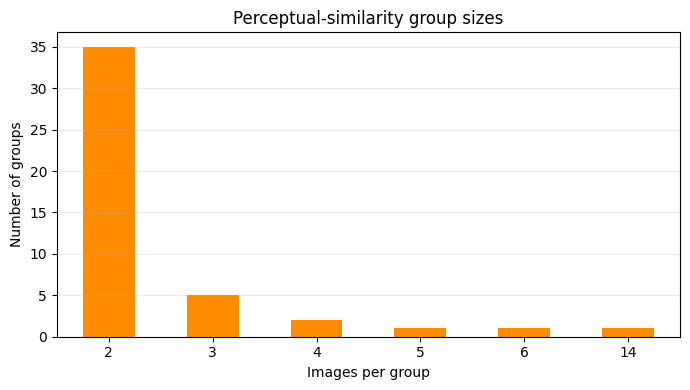

In [93]:
if not near_duplicate_groups.empty:
    ax = near_duplicate_groups.value_counts().sort_index().plot.bar(figsize=(7, 4), color="darkorange")
    ax.set(
        title="Perceptual-similarity group sizes",
        xlabel="Images per group",
        ylabel="Number of groups",
    )
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

similarity_0410: 4 visually similar images


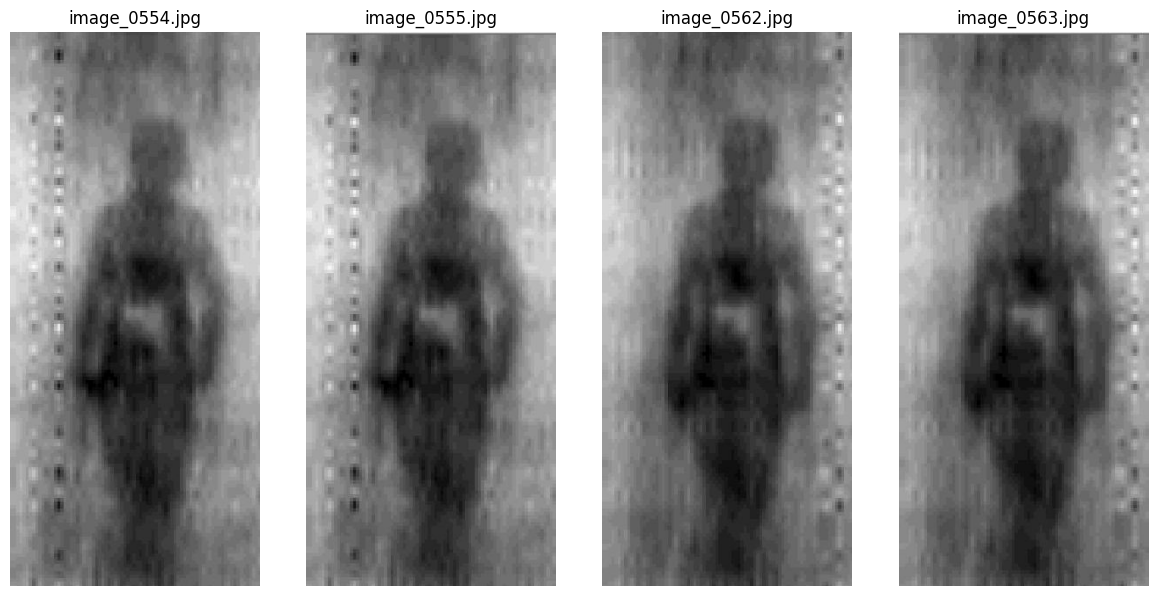

In [94]:
NEAR_DUPLICATE_REVIEW_GROUP = 4

if near_duplicate_groups.empty:
    print("No near-duplicate groups found at this threshold.")
elif not 1 <= NEAR_DUPLICATE_REVIEW_GROUP <= len(near_duplicate_groups):
    raise ValueError(f"Choose a group from 1 to {len(near_duplicate_groups)}.")
else:
    group_id = near_duplicate_groups.index[NEAR_DUPLICATE_REVIEW_GROUP - 1]
    group_images = training_images.loc[
        training_images["similarity_group"] == group_id, "image_name"
    ].tolist()
    print(f"{group_id}: {len(group_images)} visually similar images")
    show_images(group_images, columns=min(6, len(group_images)))

## 9. Create an 80/10/10 leakage-safe split

Similarity groups are assigned as complete units to ten balanced folds. One fold becomes validation, one becomes testing, and the remaining eight become training. This preserves an approximately 80/10/10 ratio while preventing similar frames from crossing splits.

In [95]:
N_FOLDS = 10
rng = np.random.default_rng(SEED)

group_stats = training_images.groupby("similarity_group").agg(
    image_count=("image_name", "size"),
    positive_count=("has_gun", "sum"),
)
group_stats["negative_count"] = group_stats["image_count"] - group_stats["positive_count"]
group_stats["class_imbalance"] = abs(group_stats["positive_count"] - group_stats["negative_count"])
group_stats["tie_breaker"] = rng.random(len(group_stats))
group_stats = group_stats.sort_values(
    ["image_count", "class_imbalance", "tie_breaker"], ascending=False
)

balance_columns = ["image_count", "positive_count", "negative_count"]
fold_targets = group_stats[balance_columns].sum().to_numpy(dtype=float) / N_FOLDS
fold_counts = np.zeros((N_FOLDS, len(balance_columns)), dtype=float)
group_to_fold = {}

for group_id, group in group_stats.iterrows():
    values = group[balance_columns].to_numpy(dtype=float)
    scores = []
    for fold in range(N_FOLDS):
        candidate = fold_counts.copy()
        candidate[fold] += values
        scores.append(np.square((candidate - fold_targets) / np.maximum(fold_targets, 1)).sum())
    chosen_fold = int(np.argmin(scores))
    group_to_fold[group_id] = chosen_fold
    fold_counts[chosen_fold] += values

training_images["fold"] = training_images["similarity_group"].map(group_to_fold)
training_images["split"] = np.select(
    [training_images["fold"] == 0, training_images["fold"] == 1],
    ["val", "test"],
    default="train",
)

assert training_images["fold"].notna().all()
assert training_images.groupby("similarity_group")["split"].nunique().max() == 1
assert set(training_images["split"]) == {"train", "val", "test"}

In [96]:
split_statistics = training_images.groupby("split").agg(
    images=("image_name", "size"),
    gun_positive=("has_gun", "sum"),
    similarity_groups=("similarity_group", "nunique"),
).reindex(["train", "val", "test"])
split_statistics["gun_negative"] = split_statistics["images"] - split_statistics["gun_positive"]
split_statistics["percentage"] = 100 * split_statistics["images"] / len(training_images)
split_statistics = split_statistics[[
    "images", "gun_positive", "gun_negative", "similarity_groups", "percentage"
]]
display(split_statistics.round({"percentage": 1}))
print("Similarity groups crossing splits: 0")

,images,gun_positive,gun_negative,similarity_groups,percentage
split,,,,,
train,905,477,428,848,79.9
val,114,60,54,106,10.1
test,113,59,54,105,10.0


Similarity groups crossing splits: 0


## 10. Convert the data to YOLO format

YOLO uses one text file for every image. Each object occupies one line in the form `class_id x_center y_center width height`. Here, `class_id` is always `0` for gun. The four box values are divided by the image width or height, so they range from 0 to 1 regardless of image resolution. A gun-free image receives an empty text file. Ultralytics YOLO reads these files during training to learn both whether a gun is present and where its bounding box should be predicted.

In [97]:
import shutil

OUTPUT_ROOT = DATASET_ROOT.parent / "processed"
for split in ("train", "val", "test"):
    for folder in (OUTPUT_ROOT / "images" / split, OUTPUT_ROOT / "labels" / split):
        folder.mkdir(parents=True, exist_ok=True)
        for old_file in folder.iterdir():
            if old_file.is_file():
                old_file.unlink()

boxes_by_image = {name: boxes for name, boxes in gun_annotations.groupby("image_name")}

def yolo_line(box):
    x_center = (box.xmin + box.xmax) / (2 * box.width)
    y_center = (box.ymin + box.ymax) / (2 * box.height)
    box_width = (box.xmax - box.xmin) / box.width
    box_height = (box.ymax - box.ymin) / box.height
    return f"0 {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}"

for image in training_images.itertuples(index=False):
    output_image = OUTPUT_ROOT / "images" / image.split / image.image_name
    output_label = OUTPUT_ROOT / "labels" / image.split / f"{Path(image.image_name).stem}.txt"
    shutil.copy2(image.image_path, output_image)
    boxes = boxes_by_image.get(image.image_name)
    lines = [] if boxes is None else [yolo_line(box) for box in boxes.itertuples(index=False)]
    output_label.write_text("\n".join(lines), encoding="utf-8")

manifest_columns = ["image_name", "split", "has_gun", "similarity_group", "sha256"]
training_images[manifest_columns].to_csv(OUTPUT_ROOT / "split_manifest.csv", index=False)

dataset_yaml = f'''path: "{OUTPUT_ROOT.resolve().as_posix()}"
train: images/train
val: images/val
test: images/test
names:
  0: gun
'''
(OUTPUT_ROOT / "dataset.yaml").write_text(dataset_yaml, encoding="utf-8")
print(f"YOLO dataset created at: {OUTPUT_ROOT.resolve()}")

YOLO dataset created at: C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed


In [98]:
for split in ("train", "val", "test"):
    image_files = sorted((OUTPUT_ROOT / "images" / split).glob("*.jpg"))
    label_files = sorted((OUTPUT_ROOT / "labels" / split).glob("*.txt"))
    assert {path.stem for path in image_files} == {path.stem for path in label_files}
    assert len(image_files) == (training_images["split"] == split).sum()

    for label_file in label_files:
        for line in label_file.read_text(encoding="utf-8").splitlines():
            class_id, x_center, y_center, width, height = map(float, line.split())
            assert class_id == 0
            assert 0 <= x_center <= 1 and 0 <= y_center <= 1
            assert 0 < width <= 1 and 0 < height <= 1

empty_labels = sum(
    not label.read_text(encoding="utf-8").strip()
    for label in (OUTPUT_ROOT / "labels").glob("*/*.txt")
)
assert empty_labels == (~training_images["has_gun"]).sum()
assert training_images.groupby("similarity_group")["split"].nunique().max() == 1

print(f"Images and label files validated: {len(training_images):,}")
print(f"Empty negative label files:       {empty_labels:,}")
print("YOLO class and coordinates:       valid")
print("Similarity-group leakage:         none")

Images and label files validated: 1,132
Empty negative label files:       536
YOLO class and coordinates:       valid
Similarity-group leakage:         none
